In [1]:
from scipy.cluster.hierarchy import linkage,dendrogram
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from sklearn.decomposition import PCA
import os 
os.chdir("E:/Machine_Learning/Datasets")

In [2]:
milk = pd.read_csv('milk.csv',index_col=0)
milk.head()

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,90.1,2.6,1.0,6.9,0.35
ORANGUTAN,88.5,1.4,3.5,6.0,0.24
MONKEY,88.4,2.2,2.7,6.4,0.18
DONKEY,90.3,1.7,1.4,6.2,0.40
HIPPO,90.4,0.6,4.5,4.4,0.10


In [3]:
scaler = StandardScaler().set_output(transform='pandas')
scl_milk = scaler.fit_transform(milk)

In [4]:
sc = AgglomerativeClustering(n_clusters=3)
sc.fit(scl_milk)
sc.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1,
       1, 2, 2])

In [5]:
new_milk = milk.copy()
new_milk['cluster'] = sc.labels_
new_milk

,water,protein,fat,lactose,ash,cluster
Animal,,,,,,
HORSE,90.1,2.6,1.0,6.9,0.35,0
ORANGUTAN,88.5,1.4,3.5,6.0,0.24,0
MONKEY,88.4,2.2,2.7,6.4,0.18,0
DONKEY,90.3,1.7,1.4,6.2,0.40,0
HIPPO,90.4,0.6,4.5,4.4,0.10,0
CAMEL,87.7,3.5,3.4,4.8,0.71,0
BISON,86.9,4.8,1.7,5.7,0.90,0
BUFFALO,82.1,5.9,7.9,4.7,0.78,0
GUINEA PIG,81.9,7.4,7.2,2.7,0.85,0


In [6]:
clusters = [2,3,4,5,6,7]
scores = []
for c in clusters:
    hc = AgglomerativeClustering(n_clusters=c)
    hc.fit(scl_milk)
    scores.append([c,silhouette_score(scl_milk,hc.labels_)])
df_scores = pd.DataFrame(scores,columns = ["clusters","score"])
df_scores.sort_values(by ='score',ascending=False)

,clusters,score
1,3,0.539160
0,2,0.525851
2,4,0.443481
3,5,0.398301
5,7,0.380407
4,6,0.375007


In [7]:
prcomp = PCA().set_output(transform='pandas')
pca_data = prcomp.fit_transform(scl_milk)
pca_data

,pca0,pca1,pca2,pca3,pca4
Animal,,,,,
HORSE,2.435175,-0.231478,0.330150,0.307664,0.048184
ORANGUTAN,2.258736,-0.693148,0.029035,-0.081057,-0.000532
MONKEY,2.335861,-0.663328,0.101257,0.247997,0.010109
DONKEY,2.318677,-0.273815,0.109881,-0.092873,-0.006769
HIPPO,2.060294,-1.019199,-0.762436,-0.510091,0.029382
CAMEL,1.301536,0.137303,-0.198742,-0.282160,-0.014668
BISON,1.282742,0.622667,0.253785,0.065148,-0.044486
BUFFALO,0.505068,0.088235,0.008383,0.133774,0.083806
GUINEA PIG,-0.255502,0.287373,-0.881857,-0.013100,-0.016484


In [8]:
sc = AgglomerativeClustering(n_clusters=3)
sc.fit(scl_milk)
pca_data['Cluster'] = sc.labels_

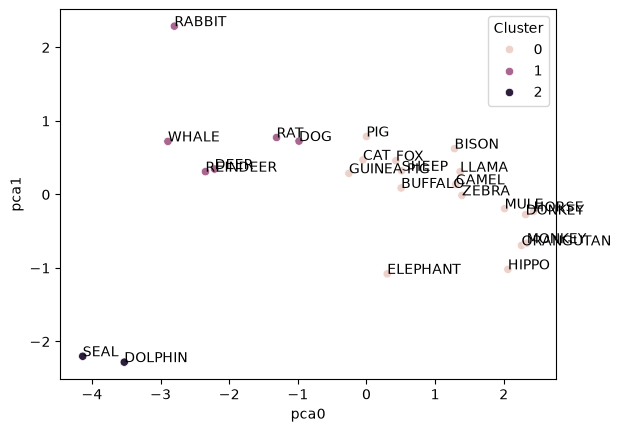

In [9]:
sns.scatterplot(pca_data,x = 'pca0',y = 'pca1',hue = 'Cluster')
for i in range(len(milk)):
    plt.text(pca_data['pca0'].iloc[i],pca_data['pca1'].iloc[i],milk.index[i])
plt.show()

## Neutrients

In [12]:
neu = pd.read_csv('nutrient.csv',index_col=0)
neu.head()

,energy,protein,fat,calcium,iron
Food_Item,,,,,
BEEF BRAISED,340,20,28,9,2.6
HAMBURGER,245,21,17,9,2.7
BEEF ROAST,420,15,39,7,2.0
BEEF STEAK,375,19,32,9,2.6
BEEF CANNED,180,22,10,17,3.7


In [13]:
scaler = StandardScaler().set_output(transform='pandas')
scl_neu = scaler.fit_transform(neu)

In [17]:
clusters = [2,3,4,5,6,7]
scores = []
for c in clusters:
    hc = AgglomerativeClustering(n_clusters=c)
    hc.fit(scl_neu)
    scores.append([c,silhouette_score(scl_neu,hc.labels_)])
df_scores = pd.DataFrame(scores,columns = ["clusters","score"])
df_scores.sort_values(by ='score',ascending=False)

,clusters,score
2,4,0.415801
1,3,0.403730
3,5,0.371724
4,6,0.359013
5,7,0.334073
0,2,0.325786


In [19]:
prcomp = PCA().set_output(transform='pandas')
pca_data = prcomp.fit_transform(scl_neu)
pca_data.head()

,pca0,pca1,pca2,pca3,pca4
Food_Item,,,,,
BEEF BRAISED,1.894907,0.318029,-0.003579,0.327156,0.005915
HAMBURGER,0.659812,-0.079563,-0.512841,0.166202,-0.002632
BEEF ROAST,2.936755,1.122724,1.097788,-0.226335,0.003483
BEEF STEAK,2.321069,0.585663,0.239173,0.318095,0.028400
BEEF CANNED,-0.256477,0.054382,-1.168707,0.474857,-0.042641


In [27]:
hc = AgglomerativeClustering(n_clusters=4)
hc.fit(scl_neu)


,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",4
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" and ""l2"" are accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and metric is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'ward'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False
Name,Type,Value
"children_ children_: array-like of shape (n_samples-1, 2)The children of each non-leaf node. Values less than `n_samples`correspond to leaves of the tree which are the original samples.A node `i` greater than or equal to `n_samples

In [28]:
pca_data['Cluster'] = hc.labels_
pca_data

,pca0,pca1,pca2,pca3,pca4,Cluster
Food_Item,,,,,,
BEEF BRAISED,1.894907,0.318029,-0.003579,0.327156,0.005915,1
HAMBURGER,0.659812,-0.079563,-0.512841,0.166202,-0.002632,0
BEEF ROAST,2.936755,1.122724,1.097788,-0.226335,0.003483,1
BEEF STEAK,2.321069,0.585663,0.239173,0.318095,0.028400,1
BEEF CANNED,-0.256477,0.054382,-1.168707,0.474857,-0.042641,0
CHICKEN BROILED,-0.932996,-0.905719,-0.393767,-0.815849,-0.031897,0
CHICKEN CANNED,-0.185016,-1.564189,-0.789681,0.039419,-0.015362,0
BEEF HEART,-0.699024,0.346282,-2.595080,1.568667,0.045738,0
LAMB LEG ROAST,0.937389,0.108904,-0.274877,0.082978,-0.024877,0


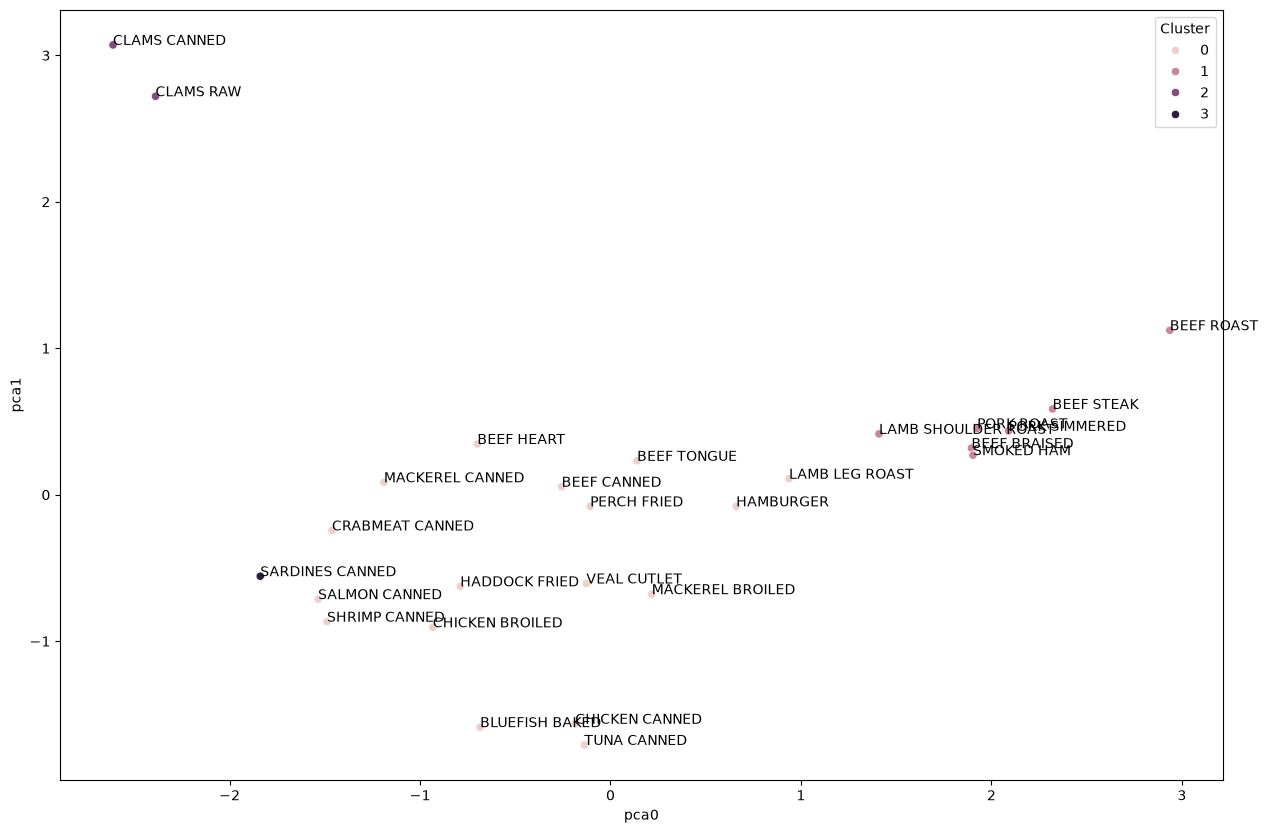

In [30]:
plt.figure(figsize=(15,10))
sns.scatterplot(pca_data,x = 'pca0',y = 'pca1',hue = 'Cluster')
for i in range(len(neu)):
    plt.text(pca_data['pca0'].iloc[i],pca_data['pca1'].iloc[i],neu.index[i])
plt.show()